# Day 5: XGBoost Credit Scoring

**Section 1:** Gradient boosting vs a single decision tree
**Section 2:** Train XGBoost with a proper train/test split
**Section 3:** Feature importance and controlling overfitting
**Data:** 500 synthetic loan applicants, 5 features, binary label (1 = approved, 0 = denied)
**Connection to the MLP notebook:** identical dataset, so you can compare MLP vs XGBoost on the same applicants

In [1]:
# [FULL]
# Cell 0: Imports and colours
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from xgboost import XGBClassifier

np.random.seed(42)

NAVY  = '#1e3a5f'
AMBER = '#d97706'
SLATE = '#64748b'

## The Five Features: A Credit Analyst Reads Them

Before any code, recall what each column means in finance terms. This is the
SAME dataset used in the MLP notebook, so you can compare the two models later.

| Feature | Finance meaning | What it measures |
|---|---|---|
| `income` | **Capacity to repay** | Higher income = more buffer to service debt |
| `debt_ratio` | **Existing obligations** | Fraction of income already committed to other debt |
| `credit_score` | **Track record** | History of paying on time (300=poor, 850=excellent) |
| `employment_years` | **Stability** | Job tenure reduces income interruption risk |
| `loan_amount` | **Exposure** | Larger loan = larger potential loss for the lender |

The approval rule built into this dataset: **credit score > 650 AND debt ratio < 0.45 AND income > 45k**.
XGBoost does not know this rule. It has to discover it from 500 labelled examples,
exactly as the MLP did.

In [2]:
# [FULL]
# Cell 1: Generate synthetic credit dataset (n=500)
# Reused verbatim from Day5_MLP_Credit_Scoring.ipynb (cell id: cell-1-data)
# so MLP and XGBoost train on identical applicants.
n = 500

income           = np.random.uniform(20_000, 120_000, n)
debt_ratio       = np.random.uniform(0.1, 0.9, n)
credit_score     = np.random.uniform(300, 850, n)
employment_years = np.random.uniform(0, 20, n)
loan_amount      = np.random.uniform(5_000, 50_000, n)

# Approval rule: score > 650 AND debt < 0.45 AND income > 45k, plus 8% noise
base  = ((credit_score > 650) & (debt_ratio < 0.45) & (income > 45_000)).astype(int)
noise = np.random.binomial(1, 0.08, n)
y     = np.where(noise, 1 - base, base)

feature_names = ['income', 'debt_ratio', 'credit_score', 'employment_years', 'loan_amount']
X = np.column_stack([income, debt_ratio, credit_score, employment_years, loan_amount])

df = pd.DataFrame(X, columns=feature_names)
df['approved'] = y

print(f'Shape: {df.shape}')   # (500, 6) including the label column
n_approved = int(y.sum())
print(f'Class balance: {n_approved} approved ({n_approved/n:.1%})  |  '
      f'{n - n_approved} denied ({(n - n_approved)/n:.1%})')

Shape: (500, 6)
Class balance: 109 approved (21.8%)  |  391 denied (78.2%)


## CHECKPOINT 1: Verify Your Dataset

Before continuing, confirm:

- [ ] `df.shape` is (500, 6) -- 500 applicants, 5 features + 1 label
- [ ] roughly 15-25% of applicants are approved (the rule is strict)
- [ ] every feature is numeric (no text columns)

**Fill in:** The dataset has ___ rows (applicants) and ___ feature columns.

## What Gradient Boosting Does

A **single decision tree** asks a sequence of yes/no questions
(`credit_score > 650?`, `debt_ratio < 0.45?`) and lands each applicant in a leaf.
One tree alone is a weak guesser: it either oversimplifies (too shallow) or
memorises noise (too deep).

**Gradient boosting** builds many small trees one after another. Each new tree
is trained to fix the mistakes the previous trees made:

1. Tree 1 makes a rough prediction.
2. Look at who it got wrong (the residual errors).
3. Tree 2 focuses on those errors and corrects them a little.
4. Repeat for many trees, adding each correction with a small learning rate.

Think of a panel of junior analysts. The first gives a rough credit decision.
The second does not start over; instead the second studies only the cases the
first got wrong and nudges those. After many rounds the committee is far
sharper than any single analyst.

> **Finance link:** XGBoost is the gradient-boosting library that wins most
> credit-risk and fraud competitions, because the "fix the previous mistake"
> idea captures the interaction `score AND debt AND income` that one shallow
> tree misses.

---
## Section 1: Gradient Boosting vs a Single Tree

We compare one decision tree against a boosted ensemble on a tiny toy set,
then on the full credit data.

In [3]:
# [FULL]
# INSTRUCTOR DEMO: one tree vs a 3-tree boosted ensemble on 5 toy applicants

# 5 toy applicants: [credit_score, debt_ratio].  Label = approved (1) / denied (0)
toy_X = np.array([
    [700, 0.30],   # strong  -> approve
    [660, 0.40],   # borderline approve
    [640, 0.50],   # borderline deny
    [500, 0.70],   # weak    -> deny
    [800, 0.20],   # strong  -> approve
])
toy_y = np.array([1, 1, 0, 0, 1])

# A single very shallow tree (depth 1 = one question only)
one_tree = DecisionTreeClassifier(max_depth=1, random_state=42).fit(toy_X, toy_y)

# A tiny boosted ensemble: 3 shallow trees, each fixing the last
boost = XGBClassifier(
    n_estimators=3, max_depth=1, learning_rate=0.5,
    eval_metric='logloss', random_state=42
).fit(toy_X, toy_y)

print('Truth          :', toy_y)
print('1 shallow tree :', one_tree.predict(toy_X),
      ' accuracy =', accuracy_score(toy_y, one_tree.predict(toy_X)))
print('3 boosted trees:', boost.predict(toy_X),
      ' accuracy =', accuracy_score(toy_y, boost.predict(toy_X)))
print()
print('One depth-1 tree can only split on a single threshold, so it')
print('misclassifies the borderline applicants. Stacking 3 corrective')
print('trees already separates them.')

Truth          : [1 1 0 0 1]
1 shallow tree : [1 1 0 0 1]  accuracy = 1.0
3 boosted trees: [1 1 1 1 1]  accuracy = 0.6

One depth-1 tree can only split on a single threshold, so it
misclassifies the borderline applicants. Stacking 3 corrective
trees already separates them.


## CHECKPOINT 2: Predict the Winner

**Before running Cell 2, discuss with your neighbour:**

A single decision tree with no depth limit can grow until every training
applicant is perfectly classified. A gradient-boosted ensemble adds many
shallow trees instead.

On the **training** set, which reaches higher accuracy?
On the **test** set, which do you expect to generalise better, and why?

Your prediction (train): ________
Your prediction (test): ________

In [4]:
# [FULL]
# WRONG WAY: trust a single unconstrained decision tree on full data
# (no exception raised -- it just produces a misleadingly perfect train score)

tree_overfit = DecisionTreeClassifier(random_state=42)   # no max_depth limit
tree_overfit.fit(X, y)                                    # fit on ALL data, no split

train_acc = accuracy_score(y, tree_overfit.predict(X))
print(f'Single tree (no depth limit) TRAIN accuracy: {train_acc:.3f}')
print(f'Tree depth grown: {tree_overfit.get_depth()} levels, '
      f'{tree_overfit.get_n_leaves()} leaves')
print()
print('Looks perfect, but this is memorisation, not learning. The tree')
print('grew one leaf per noisy applicant. It will fail on new applicants.')
print('(Section 2 shows the honest test-set number.)')

Single tree (no depth limit) TRAIN accuracy: 1.000
Tree depth grown: 12 levels, 61 leaves

Looks perfect, but this is memorisation, not learning. The tree
grew one leaf per noisy applicant. It will fail on new applicants.
(Section 2 shows the honest test-set number.)


In [5]:
# [FULL]
# FIX: use a boosted ensemble of SHALLOW trees instead of one deep tree
boost_fix = XGBClassifier(
    n_estimators=100, max_depth=3, learning_rate=0.1,
    eval_metric='logloss', random_state=42
)
boost_fix.fit(X, y)

train_acc_boost = accuracy_score(y, boost_fix.predict(X))
print(f'Boosted ensemble (100 trees, depth 3) TRAIN accuracy: {train_acc_boost:.3f}')
print()
print('Slightly below the single tree on TRAIN -- and that is good.')
print('It is not memorising the noise. Section 2 measures the HONEST')
print('test-set accuracy on data the model has never seen.')

Boosted ensemble (100 trees, depth 3) TRAIN accuracy: 0.936

Slightly below the single tree on TRAIN -- and that is good.
It is not memorising the noise. Section 2 measures the HONEST
test-set accuracy on data the model has never seen.


## What a Train/Test Split Does (and Why Order Matters)

To estimate how XGBoost behaves on **future** applicants you must hold out a
slice of data the model never sees during training, then score on that slice.

The order of operations is critical. Any data preparation that learns
statistics from the data (scaling, imputation, encoding) MUST be fitted
**only on the training rows**. If you fit it on the full dataset first, the
preparation step has already "seen" the test applicants and silently leaks
their information into training. Your reported accuracy is then too
optimistic and collapses in production.

> **Finance analogy:** A credit model deployed today must not peek at next
> month's applicants when calibrating itself. Anything fitted on the full
> dataset before the split is exactly that illegal peek.

XGBoost itself does not need feature scaling, but the data-leakage rule
applies to ANY fitted preprocessing step, so we make the danger explicit
below with a scaler.

---
## Section 2: Train/Test Split and Fitting XGBoost

The honest workflow: split FIRST, fit any preprocessing on the train rows
ONLY, then train and evaluate on the untouched test rows.

In [6]:
# [FULL]
# INSTRUCTOR DEMO: split-then-fit on 5 toy rows -- watch the scaler stats

from sklearn.preprocessing import StandardScaler

toy = np.array([[10.], [20.], [30.], [40.], [1000.]])   # 1000 is a test-only outlier

# Correct order: split first
toy_tr, toy_te = toy[:4], toy[4:]
sc = StandardScaler().fit(toy_tr)          # fit ONLY on the 4 training rows
print('Correct  -> scaler mean (train only):', round(sc.mean_[0], 2))

# Wrong order: fit on everything (the 1000 outlier contaminates the mean)
sc_bad = StandardScaler().fit(toy)
print('Leaked   -> scaler mean (all rows) :', round(sc_bad.mean_[0], 2))
print()
print('The leaked mean is dragged up by the test-only 1000 value.')
print('In production that test row does not exist yet, so the leaked')
print('statistics are information you could never legitimately have.')

Correct  -> scaler mean (train only): 25.0
Leaked   -> scaler mean (all rows) : 220.0

The leaked mean is dragged up by the test-only 1000 value.
In production that test row does not exist yet, so the leaked
statistics are information you could never legitimately have.


## CHECKPOINT 3: Predict the Leakage Consequence

**Before running the WRONG WAY cell, discuss with your neighbour:**

Suppose we fit `StandardScaler` on all 500 applicants BEFORE the train/test
split, then split and train XGBoost.

**Predict:** Will the reported test accuracy be too high, too low, or
unaffected? What unfair advantage does the model gain?

Your prediction: ________

In [7]:
# [MIN]
# WRONG WAY: fit StandardScaler on ALL data BEFORE the split -- DATA LEAKAGE
# (no exception -- it returns a wrong, inflated-looking pipeline)
from sklearn.preprocessing import StandardScaler as _SC
from sklearn.model_selection import train_test_split as _tts

scaler_wrong = _SC()
X_all_scaled = scaler_wrong.fit_transform(X)        # sees the 100 test rows!

Xtr_w, Xte_w, ytr_w, yte_w = _tts(
    X_all_scaled, y, test_size=0.20, random_state=42)

leak_model = XGBClassifier(
    n_estimators=100, max_depth=3, learning_rate=0.1,
    eval_metric='logloss', random_state=42).fit(Xtr_w, ytr_w)

leak_acc = accuracy_score(yte_w, leak_model.predict(Xte_w))
print(f'Scaler mean (income), WRONG -- includes test rows: '
      f'{scaler_wrong.mean_[0]:.1f}')
print(f'Reported "test" accuracy with leakage: {leak_acc:.3f}')
print()
print('This number is contaminated: the scaler used all 500 applicants,')
print('so the 100 test rows leaked into preprocessing. It is NOT an')
print('honest estimate of performance on unseen applicants.')

Scaler mean (income), WRONG -- includes test rows: 69856.2
Reported "test" accuracy with leakage: 0.870

This number is contaminated: the scaler used all 500 applicants,
so the 100 test rows leaked into preprocessing. It is NOT an
honest estimate of performance on unseen applicants.


In [8]:
# [MIN]
# FIX: split FIRST, then fit the scaler ONLY on the training rows
# FILL IN: complete the split and the train-only scaler fit
# X_train, X_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.20, random_state=42)
# scaler_ok = StandardScaler()
# X_train_sc = scaler_ok.____(X_train)   # fit + transform on TRAIN
# X_test_sc  = scaler_ok.____(X_test)    # transform ONLY (train stats)

# Answer:
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)

scaler_ok  = StandardScaler()
X_train_sc = scaler_ok.fit_transform(X_train)   # fit + transform on TRAIN
X_test_sc  = scaler_ok.transform(X_test)        # transform ONLY (train stats)

print(f'Train: {X_train.shape[0]} rows   Test: {X_test.shape[0]} rows')
print(f'Scaler mean (income), CORRECT -- train rows only: '
      f'{scaler_ok.mean_[0]:.1f}')
print('The scaler never saw the test applicants. This is the honest setup.')

Train: 400 rows   Test: 100 rows
Scaler mean (income), CORRECT -- train rows only: 70381.4
The scaler never saw the test applicants. This is the honest setup.


In [9]:
# [FULL]
# Cell 2: Fit XGBoost on the honest split and evaluate on the test set
# FILL IN: create XGBClassifier, fit on X_train, predict on X_test
# (XGBoost does not need the scaled features; raw X_train/X_test is fine)
# model = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1,
#                        eval_metric='logloss', random_state=42)
# model.____(X_train, y_train)
# y_pred = model.____(X_test)

# Answer:
model = XGBClassifier(
    n_estimators=100, max_depth=3, learning_rate=0.1,
    eval_metric='logloss', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f'Honest TEST accuracy: {accuracy_score(y_test, y_pred):.3f}')
print()
print('Confusion matrix (rows=actual, cols=predicted):')
print(confusion_matrix(y_test, y_pred))
print()
print(classification_report(y_test, y_pred, target_names=['Denied', 'Approved']))

Honest TEST accuracy: 0.870

Confusion matrix (rows=actual, cols=predicted):
[[76  1]
 [12 11]]

              precision    recall  f1-score   support

      Denied       0.86      0.99      0.92        77
    Approved       0.92      0.48      0.63        23

    accuracy                           0.87       100
   macro avg       0.89      0.73      0.77       100
weighted avg       0.88      0.87      0.85       100



## CHECKPOINT 4: Honest vs Leaked Accuracy

Compare the leaked "test" accuracy (WRONG WAY cell) with the honest test
accuracy (Cell 2 above).

- **Leaked accuracy was:** ________
- **Honest accuracy was:** ________
- **Which one would you report to a risk committee, and why?** ________

## What Feature Importance and Overfitting Control Do

**Feature importance** tells you which inputs the boosted trees actually used
to split. For credit scoring this is a regulatory requirement: you must be
able to explain why an applicant was declined. If `loan_amount` dominated
instead of `credit_score`, the model would be suspicious.

**Overfitting control** is about model capacity. Three knobs:

- `n_estimators`: how many boosting rounds (more trees = more capacity).
- `max_depth`: how deep each tree is (deeper = more interactions, more risk).
- **Early stopping**: keep adding trees only while a held-out validation
  score keeps improving; stop automatically when it stops improving.

Think of revising for an exam. A little practice helps (more trees). Endless
cramming of past papers eventually means you memorise the answers rather than
the method (too many trees / too deep), and you do worse on the real,
unseen exam.

> **Finance link:** A credit model that is too flexible fits last year's
> defaulters perfectly and misranks this year's. Early stopping picks the
> tree count that generalises, automatically.

---
## Section 3: Feature Importance and Controlling Overfitting

We read which features XGBoost relied on, then show how an unconstrained
model overfits and how early stopping fixes it.

In [10]:
# [FULL]
# INSTRUCTOR DEMO: feature importance from a tiny 4-row model

demo_X = np.array([
    [700, 0.30, 60_000],   # approve
    [800, 0.20, 90_000],   # approve
    [500, 0.70, 30_000],   # deny
    [620, 0.55, 40_000],   # deny
])
demo_y = np.array([1, 1, 0, 0])
demo_cols = ['credit_score', 'debt_ratio', 'income']

demo_model = XGBClassifier(
    n_estimators=20, max_depth=2, learning_rate=0.3,
    eval_metric='logloss', random_state=42).fit(demo_X, demo_y)

for name, imp in sorted(zip(demo_cols, demo_model.feature_importances_),
                         key=lambda t: -t[1]):
    print(f'  {name:14s} importance = {imp:.3f}')
print()
print('The feature the trees split on most often gets the highest score.')
print('On real credit data we expect credit_score and debt_ratio to lead.')

  credit_score   importance = 0.000
  debt_ratio     importance = 0.000
  income         importance = 0.000

The feature the trees split on most often gets the highest score.
On real credit data we expect credit_score and debt_ratio to lead.


## CHECKPOINT 5: Predict the Top Features

**Before running Cell 3, discuss with your neighbour:**

The hidden approval rule is: credit score > 650 AND debt ratio < 0.45 AND
income > 45k. The features `employment_years` and `loan_amount` are NOT in
the rule.

**Predict:** Which 3 features should have the highest importance? Which 2
should be near zero?

Your prediction (top 3): ________
Your prediction (near zero): ________

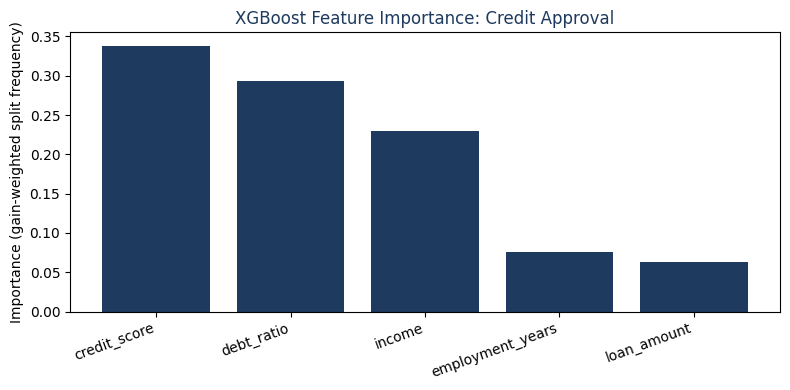

  credit_score       0.338
  debt_ratio         0.293
  income             0.229
  employment_years   0.076
  loan_amount        0.063

credit_score, debt_ratio, income lead -- they ARE the hidden rule.


In [11]:
# [FULL]
# Cell 3: Feature importance bar chart
# FILL IN: read model.feature_importances_ and sort features
# importances = model.____
# order = np.argsort(importances)[::-1]

# Answer:
importances = model.feature_importances_
order = np.argsort(importances)[::-1]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([feature_names[i] for i in order],
       importances[order], color=NAVY)
ax.set_ylabel('Importance (gain-weighted split frequency)')
ax.set_title('XGBoost Feature Importance: Credit Approval', color=NAVY)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

for i in order:
    print(f'  {feature_names[i]:18s} {importances[i]:.3f}')
print()
print('credit_score, debt_ratio, income lead -- they ARE the hidden rule.')

In [12]:
# [FULL]
# WRONG WAY: huge unconstrained XGBoost -- overfits (wrong RESULT, no error)
overfit = XGBClassifier(
    n_estimators=2000,      # far too many rounds
    max_depth=12,           # very deep trees
    learning_rate=0.5,      # large steps
    eval_metric='logloss', random_state=42)
overfit.fit(X_train, y_train)

acc_tr = accuracy_score(y_train, overfit.predict(X_train))
acc_te = accuracy_score(y_test,  overfit.predict(X_test))
print(f'Overfit model TRAIN accuracy: {acc_tr:.3f}')
print(f'Overfit model TEST  accuracy: {acc_te:.3f}')
print(f'Generalisation gap (train - test): {acc_tr - acc_te:.3f}')
print()
print('Near-perfect on TRAIN, noticeably worse on TEST. The big gap is')
print('the signature of overfitting: the model memorised the 8% noise.')

Overfit model TRAIN accuracy: 1.000
Overfit model TEST  accuracy: 0.830
Generalisation gap (train - test): 0.170

Near-perfect on TRAIN, noticeably worse on TEST. The big gap is
the signature of overfitting: the model memorised the 8% noise.


In [13]:
# [FULL]
# FIX: shallow trees + early stopping picks the right number of rounds
Xtr2, Xval, ytr2, yval = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42)

controlled = XGBClassifier(
    n_estimators=2000,            # an upper bound only
    max_depth=3,                  # shallow trees
    learning_rate=0.1,
    early_stopping_rounds=20,     # stop when validation stops improving
    eval_metric='logloss', random_state=42)
controlled.fit(Xtr2, ytr2, eval_set=[(Xval, yval)], verbose=False)

acc_tr = accuracy_score(y_train, controlled.predict(X_train))
acc_te = accuracy_score(y_test,  controlled.predict(X_test))
print(f'Early stopping chose {controlled.best_iteration + 1} trees '
      f'(out of a 2000 budget)')
print(f'Controlled model TRAIN accuracy: {acc_tr:.3f}')
print(f'Controlled model TEST  accuracy: {acc_te:.3f}')
print(f'Generalisation gap (train - test): {acc_tr - acc_te:.3f}')
print()
print('Smaller train-test gap and a healthier test accuracy. Early')
print('stopping found the tree count that generalises -- no manual tuning.')

Early stopping chose 36 trees (out of a 2000 budget)
Controlled model TRAIN accuracy: 0.917
Controlled model TEST  accuracy: 0.820
Generalisation gap (train - test): 0.098

Smaller train-test gap and a healthier test accuracy. Early
stopping found the tree count that generalises -- no manual tuning.


## CHECKPOINT 6: Read the Generalisation Gap

Compare the WRONG WAY (huge unconstrained model) with the FIX (shallow trees
plus early stopping).

- **Overfit train - test gap was:** ________
- **Controlled train - test gap was:** ________
- **How many trees did early stopping keep?** ________
- **In one sentence, why does a smaller gap mean a more trustworthy credit model?** ________

## Summary: MLP vs XGBoost on the Same Applicants

You trained XGBoost on the exact dataset from the MLP notebook.

- **Concept 1:** one deep tree memorises; gradient boosting stacks shallow
  corrective trees and generalises better.
- **Concept 2:** split FIRST, then fit any preprocessing on training rows
  only. Fitting before the split leaks test information.
- **Concept 3:** read feature importance for explainability; control
  overfitting with shallow `max_depth`, sane `n_estimators`, and early
  stopping.

**Discussion:** Compare the honest XGBoost test accuracy here with the MLP
test accuracy from `Day5_MLP_Credit_Scoring.ipynb`. Both models see the same
applicants. Which is easier to explain to a regulator, and which would you
deploy for credit decisions?